# 4. Сравнение CIFAR-10, Fashion-MNIST и Oxford Flowers 102

Тетрадь читает метки CIFAR-10 и Fashion-MNIST и использует проверенные в тетради 03 числа для Oxford Flowers 102. Никакие JSON, отчёты или скрипты не нужны. SciPy для этого сравнения не требуется.

## 4.1. Пути и библиотеки

In [1]:
from pathlib import Path
from IPython.display import display
import gzip
import pickle
import tarfile
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / 'data').exists(): root = root.parent
assert (root / 'data').exists(), 'Нужна папка CourseWork/data'
print('Данные:', root / 'data')

Данные: /mnt/c/Users/maaric/Documents/Обмен_Sid/4 курс 1 семестр/ИСИИ курсовая/CourseWork/data


## 4.2. CIFAR-10: метки и разбиение
Используем тот же `seed=42`, что в первой тетради.

In [2]:
path = root / 'data' / 'cifar-10-python.tar.gz'
with tarfile.open(path, 'r:gz') as archive:
    parts = []
    for number in range(1, 6):
        with archive.extractfile(f'cifar-10-batches-py/data_batch_{number}') as file:
            parts.append(pickle.load(file, encoding='bytes'))
    with archive.extractfile('cifar-10-batches-py/test_batch') as file:
        cifar_test = pickle.load(file, encoding='bytes')
cifar_labels = np.concatenate([part[b'labels'] for part in parts])
cifar_test_labels = np.asarray(cifar_test[b'labels'])
rng = np.random.default_rng(42)
cifar_val = np.concatenate([
    rng.choice(np.flatnonzero(cifar_labels == cls), 500, replace=False)
    for cls in range(10)
])
cifar_train = np.setdiff1d(np.arange(len(cifar_labels)), cifar_val)
print('CIFAR-10:', len(cifar_train), len(cifar_val), len(cifar_test_labels))

CIFAR-10: 45000 5000 10000


## 4.3. Fashion-MNIST: только метки
Не загружаем изображения повторно, потому что для сравнения количества объектов они не нужны.

In [3]:
folder = root / 'data' / 'fashion'
with gzip.open(folder / 'train-labels-idx1-ubyte.gz', 'rb') as file:
    raw = file.read()
assert int.from_bytes(raw[:4], 'big') == 2049
fashion_labels = np.frombuffer(raw, dtype=np.uint8, offset=8)
with gzip.open(folder / 't10k-labels-idx1-ubyte.gz', 'rb') as file:
    raw = file.read()
fashion_test_labels = np.frombuffer(raw, dtype=np.uint8, offset=8)
rng = np.random.default_rng(42)
fashion_val = np.concatenate([
    rng.choice(np.flatnonzero(fashion_labels == cls), 600, replace=False)
    for cls in range(10)
])
fashion_train = np.setdiff1d(np.arange(len(fashion_labels)), fashion_val)
print('Fashion-MNIST:', len(fashion_train), len(fashion_val), len(fashion_test_labels))

Fashion-MNIST: 54000 6000 10000


## 4.4. Oxford Flowers 102: результаты предыдущего EDA
В тетради 03 проверено официальное разбиение: 102 класса, 1020 train, 1020 val, 6149 test; по 10 изображений каждого класса в train. Используем эти **полученные ранее значения**, поэтому четвёртой тетради не нужен SciPy. Если изменить разбиение Flowers, обновите значения здесь.

In [4]:
flowers_train_counts = np.full(102, 10)
flowers_train_size = int(flowers_train_counts.sum())
flowers_val_size = 1020
flowers_test_size = 6149
print('Oxford Flowers 102:', flowers_train_size, flowers_val_size, flowers_test_size)
print('Объектов на класс в train:', flowers_train_counts.min(), '—', flowers_train_counts.max())

Oxford Flowers 102: 1020 1020 6149
Объектов на класс в train: 10 — 10


## 4.5. Сводная таблица
Для Flowers разрешение 64×64 — выбранный **вариант приведения**, а не исходный размер всех JPEG. Последний столбец — число входных значений, **не** измеренное время или память обучения.

In [5]:
names = ['CIFAR-10', 'Fashion-MNIST', 'Oxford Flowers 102']
shapes = [(32, 32, 3), (28, 28, 1), (64, 64, 3)]
class_counts = [
    np.bincount(cifar_labels[cifar_train], minlength=10),
    np.bincount(fashion_labels[fashion_train], minlength=10),
    flowers_train_counts,
]
split_sizes = [(len(cifar_train), len(cifar_val), len(cifar_test_labels)),
               (len(fashion_train), len(fashion_val), len(fashion_test_labels)),
               (flowers_train_size, flowers_val_size, flowers_test_size)]
rows = []
for name, shape, counts, (n_train, n_val, n_test) in zip(names, shapes, class_counts, split_sizes):
    rows.append((name, len(counts), '×'.join(map(str, shape)),
                 n_train, n_val, n_test, int(counts.min()), int(counts.max()), int(np.prod(shape))))
for row in rows:
    print(row)

('CIFAR-10', 10, '32×32×3', 45000, 5000, 10000, 4500, 4500, 3072)
('Fashion-MNIST', 10, '28×28×1', 54000, 6000, 10000, 5400, 5400, 784)
('Oxford Flowers 102', 102, '64×64×3', 1020, 1020, 6149, 10, 10, 12288)


## 4.6. Графики сравнения

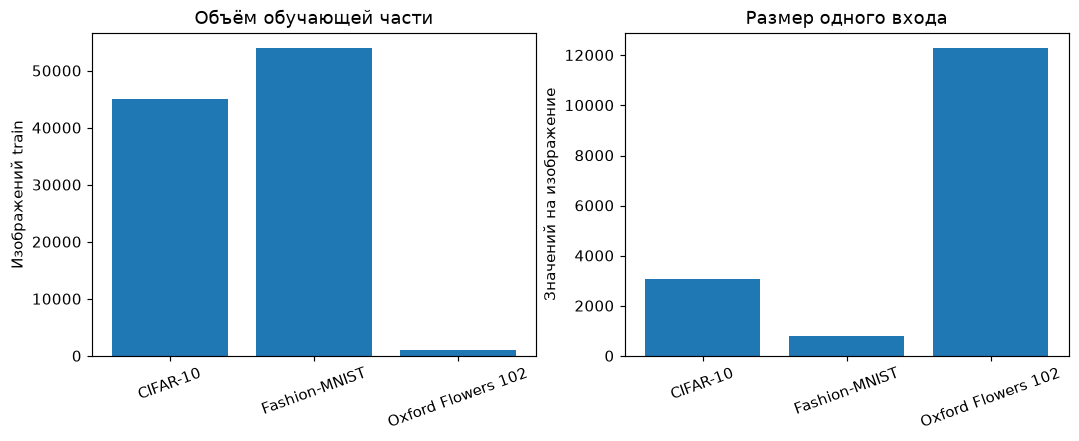

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(names, [r[3] for r in rows])
axes[0].set(ylabel='Изображений train', title='Объём обучающей части')
axes[1].bar(names, [r[-1] for r in rows])
axes[1].set(ylabel='Значений на изображение', title='Размер одного входа')
for ax in axes: ax.tick_params(axis='x', labelrotation=20)
display(fig); plt.close(fig)

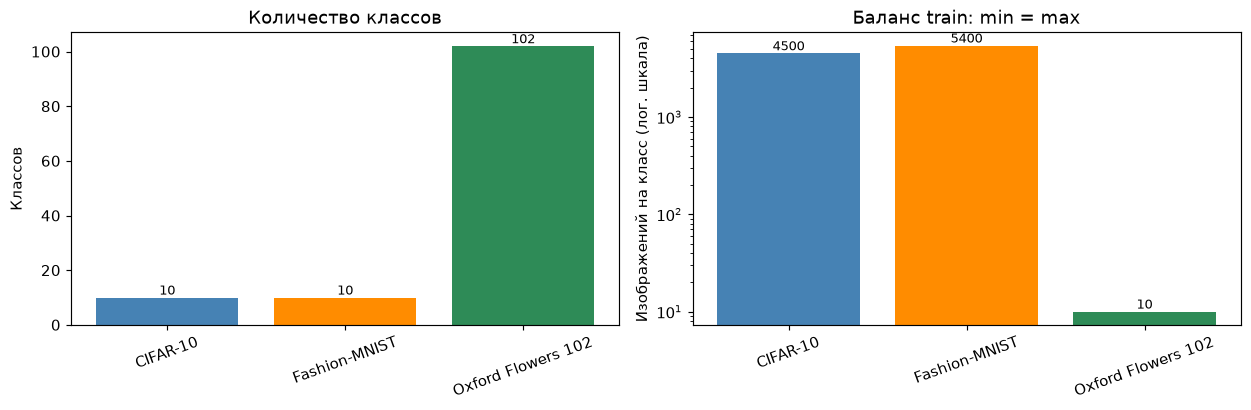

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(names, [len(counts) for counts in class_counts], color=['steelblue', 'darkorange', 'seagreen'])
axes[0].set(ylabel='Классов', title='Количество классов')
axes[1].bar(names, [counts[0] for counts in class_counts], color=['steelblue', 'darkorange', 'seagreen'])
axes[1].set_yscale('log')  # 10, 4500 и 5400 видны на одной диаграмме
axes[1].set(ylabel='Изображений на класс (лог. шкала)', title='Баланс train: min = max')
for ax in axes:
    ax.tick_params(axis='x', labelrotation=20)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.0f}',
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)
fig.tight_layout()
display(fig)
plt.close(fig)

## 4.7. Решение по результатам EDA

**Предлагаем CIFAR-10** для основного обучения DDPM: это цветные изображения, исходный размер 32×32, 45 000 train-примеров и равномерное распределение по 10 классам. Fashion-MNIST проще по разрешению и имеет больше примеров, но он одноканальный. Oxford Flowers 102 цветной, но official train намного меньше, содержит 102 класса, а фотографии разного исходного размера потребуют отдельного выбора разрешения.

Это обоснование **по данным**, а не утверждение, что CIFAR-10 даст лучший FID. FID, скорость и память измерим только после обучения модели.